# Jour 3 — Clustering hiérarchique et par densité (Chapitres 3.2 et 3.3)

Objectifs :
1. Classification hiérarchique ascendante (CAH) avec les liens **single, complete, average et Ward** ; dendrogrammes et choix de la coupure.
2. **DBSCAN** sur l'espace PCA / UMAP : réglage de $\varepsilon$ ($d^*$) et `min_samples` ($e^*$) par le graphique des k-distances ; points cœur, de bordure et bruit.
3. Limites de K-means (clusters non convexes, points isolés) face à DBSCAN.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

from src.config import SEED, K_RANGE, DATA_PROC, FIGURES, RESULTS
from src.preprocessing import load_processed
from src.metrics import knee_point

sns.set_theme(style="whitegrid", palette="tab10"); plt.rcParams["figure.dpi"] = 110
def save(fig, name): fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

d = load_processed()
idx = d["sample_idx"]; Xs = d["X_a"][idx]
U, P = d["emb_umap2"], d["emb_pca_k"]
D_gow = np.load(DATA_PROC / "D_gower_sample.npy")
d_euc = pdist(Xs, "euclidean")              # forme condensée pour scipy
d_gow = squareform(D_gow, checks=False)

## 1. CAH — quatre critères d'agrégation
- **single** : $D(A,B)=\min d(a,b)$ → effet de chaîne ; **complete** : $\max d(a,b)$ → groupes compacts ;
- **average** (UPGMA) : moyenne des distances ; **Ward** : minimise l'augmentation de l'inertie intra (euclidienne uniquement).

On applique les 4 liens sur la représentation (a) (euclidienne), et les liens compatibles (single/complete/average) sur la **matrice de Gower**. La **corrélation cophénétique** mesure la fidélité du dendrogramme aux distances d'origine.

In [2]:
Z, coph = {}, {}
for meth in ["single", "complete", "average", "ward"]:
    Z[("euclidienne", meth)] = linkage(d_euc, method=meth)
    coph[("euclidienne", meth)] = cophenet(Z[("euclidienne", meth)], d_euc)[0]
for meth in ["single", "complete", "average"]:
    Z[("gower", meth)] = linkage(d_gow, method=meth)
    coph[("gower", meth)] = cophenet(Z[("gower", meth)], d_gow)[0]
pd.Series(coph, name="corrélation cophénétique").round(3).to_frame()

corrélation cophénétique
euclidienne single                       0.662
            complete                     0.736
            average                      0.777
            ward                         0.529
gower       single                       0.411
            complete                     0.495
            average                      0.597

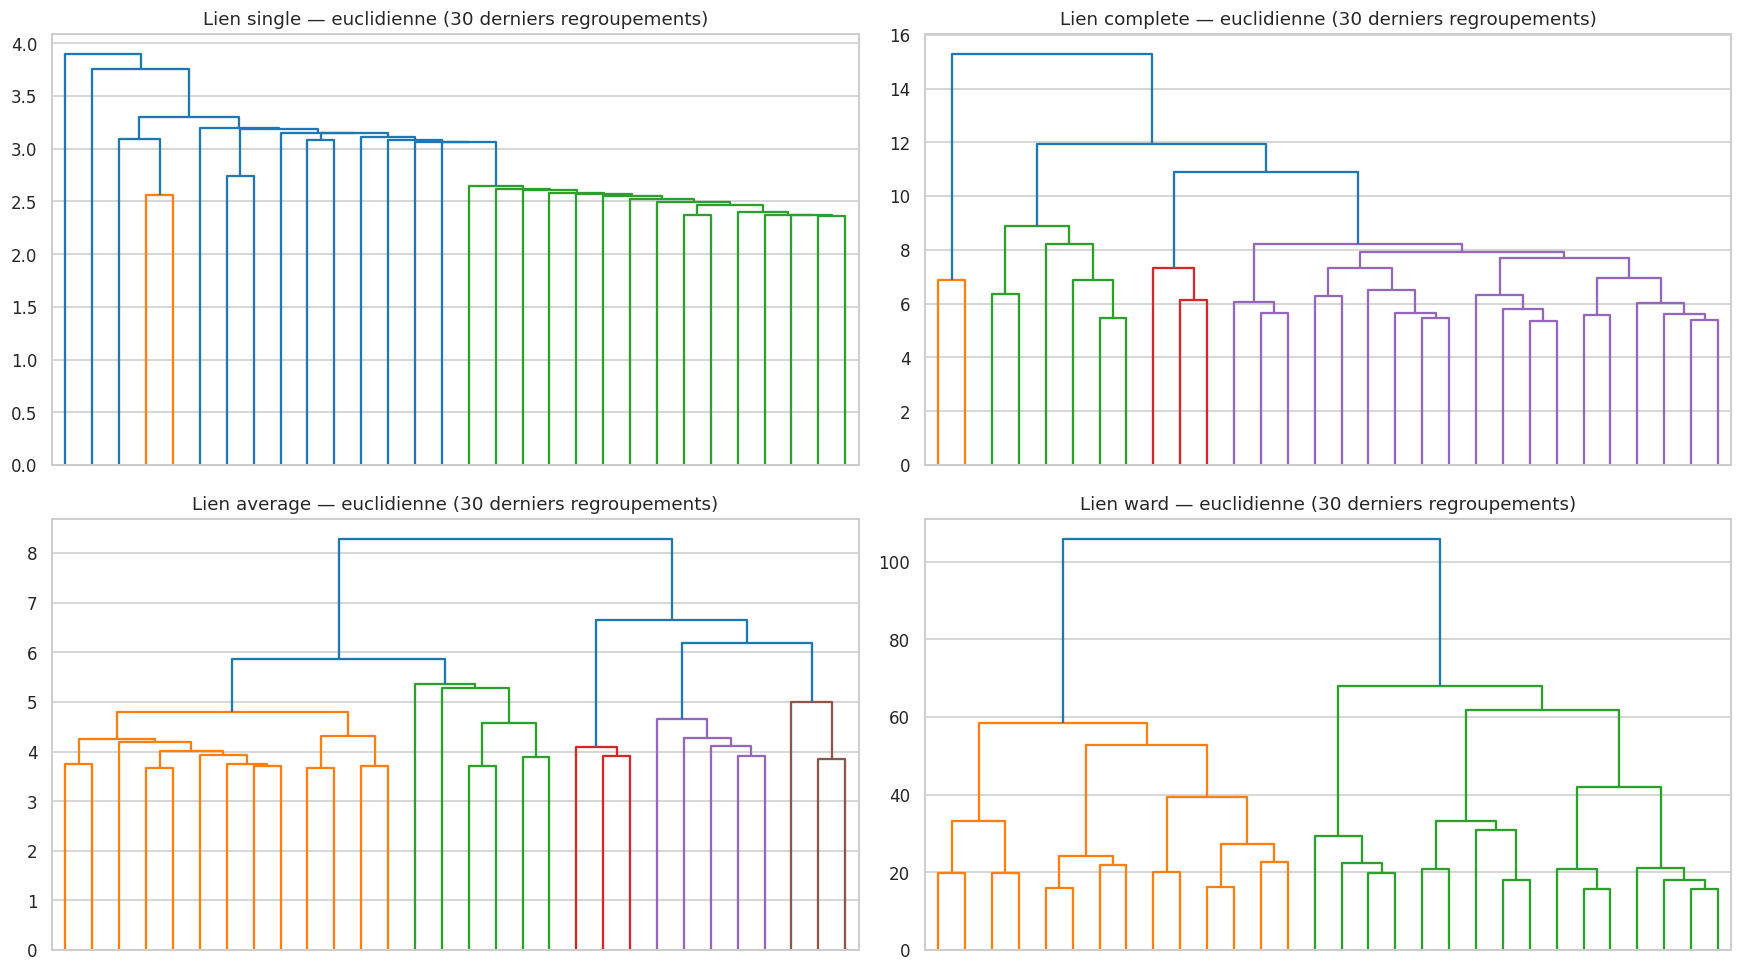

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, meth in zip(axes.ravel(), ["single", "complete", "average", "ward"]):
    dendrogram(Z[("euclidienne", meth)], truncate_mode="lastp", p=30, ax=ax, no_labels=True,
               color_threshold=None)
    ax.set_title(f"Lien {meth} — euclidienne (30 derniers regroupements)")
fig.tight_layout(); save(fig, "j3_dendrogrammes")

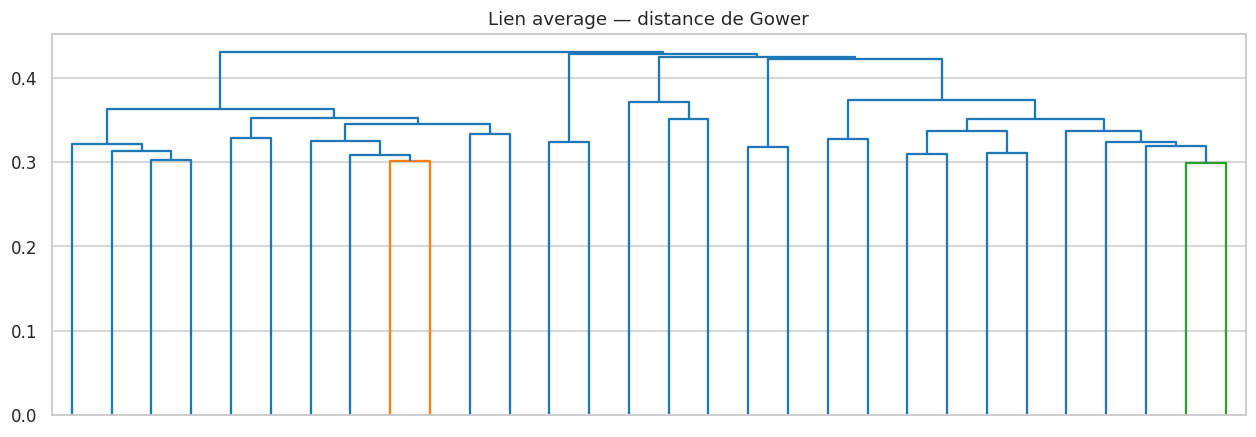

In [4]:
fig, ax = plt.subplots(figsize=(14, 4.5))
dendrogram(Z[("gower", "average")], truncate_mode="lastp", p=30, ax=ax, no_labels=True)
ax.set_title("Lien average — distance de Gower"); save(fig, "j3_dendrogramme_gower")

### Choix de la coupure
Deux critères complémentaires : (i) le **plus grand saut** de hauteur de fusion dans les derniers regroupements (coupure « naturelle » du dendrogramme), (ii) la **silhouette** pour $k\in[2,10]$.

In [5]:
rows, hac_labels = [], {}
for (dist, meth), z in Z.items():
    h = z[:, 2]
    last = h[-10:]                                   # hauteurs des 10 dernières fusions
    gaps = np.diff(last)[:-1]                        # sauts (hors fusion finale → k ≥ 2)
    k_gap = int(9 - np.argmax(gaps))                 # couper juste sous le plus grand saut
    for k in K_RANGE:
        lab = fcluster(z, k, criterion="maxclust") - 1
        hac_labels[(dist, meth, k)] = lab
        D_eval = D_gow if dist == "gower" else squareform(d_euc)
        sil = silhouette_score(D_eval, lab, metric="precomputed") if len(np.unique(lab)) > 1 else np.nan
        sizes = np.bincount(lab)
        rows.append({"distance": dist, "lien": meth, "k": k, "silhouette": sil,
                     "plus gros cluster %": 100 * sizes.max() / len(lab), "k_saut": k_gap})
hac_df = pd.DataFrame(rows)
piv = hac_df.pivot_table(index=["distance", "lien"], columns="k", values="silhouette").round(3)
piv

k                        2      3      4      5      6      7      8      9   \
distance    lien                                                               
euclidienne average   0.524  0.494  0.474  0.334  0.317  0.308  0.308  0.213   
            complete  0.619  0.392  0.323  0.313  0.200  0.187  0.165  0.131   
            single    0.682  0.680  0.549  0.475  0.445  0.445  0.446  0.310   
            ward      0.208  0.170  0.189  0.124  0.123  0.129  0.113  0.099   
gower       average   0.243  0.171  0.130  0.122  0.103  0.087  0.143  0.150   
            complete  0.175  0.154  0.092  0.088  0.085  0.108  0.123  0.122   
            single    0.205  0.140  0.112  0.069  0.061  0.008 -0.008 -0.018   

k                        10  
distance    lien             
euclidienne average   0.210  
            complete  0.111  
            single    0.310  
            ward      0.106  
gower       average   0.137  
            complete  0.112  
            single   -0.029

In [6]:
hac_df.pivot_table(index=["distance", "lien"], columns="k", values="plus gros cluster %").round(1)

k                        2      3     4     5     6     7     8     9     10
distance    lien                                                            
euclidienne average    99.1   99.1  99.1  97.9  97.9  97.9  97.9  91.7  91.7
            complete   99.8   98.0  97.1  97.1  95.2  95.2  71.2  58.9  58.9
            single    100.0  100.0  99.8  99.8  99.8  99.7  99.7  99.6  99.6
            ward       65.4   65.4  65.4  45.1  32.6  32.6  21.0  21.0  21.0
gower       average    86.0   86.0  86.0  86.0  86.0  86.0  53.0  44.9  44.9
            complete   70.8   70.8  59.0  59.0  59.0  49.1  29.0  29.0  29.0
            single    100.0  100.0  99.9  99.9  99.8  99.8  99.8  99.8  99.8

In [7]:
summary = (hac_df.groupby(["distance", "lien"])
           .apply(lambda g: pd.Series({"k_saut": g["k_saut"].iloc[0],
                                       "k_best_sil": int(g.loc[g["silhouette"].idxmax(), "k"]),
                                       "sil_max": g["silhouette"].max()}))).round(3)
summary

k_saut  k_best_sil  sil_max
distance    lien                                 
euclidienne average      4.0         2.0    0.524
            complete     3.0         2.0    0.619
            single       2.0         2.0    0.682
            ward         5.0         2.0    0.208
gower       average      4.0         2.0    0.243
            complete     6.0         2.0    0.175
            single       4.0         2.0    0.205

**Interprétation des liens**
- **Single** : silhouettes les plus élevées (0,68 à k = 2) mais **trompeuses** — le plus gros cluster contient 99,6 à 100 % des clients, les autres groupes sont des singletons isolés : c'est l'**effet de chaîne**, inutilisable pour une segmentation.
- **Average** et **complete** (euclidienne) : meilleure fidélité aux distances (corrélation cophénétique 0,78 et 0,74) mais un groupe dominant (> 95 % jusqu'à k = 7) : ces liens isolent surtout des **clients atypiques** (fort `previous`, `campaign` élevé).
- **Gower** : liens plus équilibrés mais cophénétique faible (≤ 0,60) et silhouettes basses.
- **Ward** : cophénétique plus faible (0,53, il optimise l'inertie et non la fidélité aux distances) mais des **groupes de tailles comparables** — le plus utile en marketing. Le plus grand saut de hauteur indique 5 groupes, la silhouette (k ≥ 3) culmine à **k = 4** (0,189) : on retient **Ward, k = 4** (tailles 2 616 / 603 / 325 / 456).

> Remarque : la silhouette est maximale à k = 2 pour tous les liens — partition triviale (contacté auparavant ou non) qui ne permet pas 3-4 actions marketing différenciées.

k Ward = 4 | tailles : [2616  603  325  456]


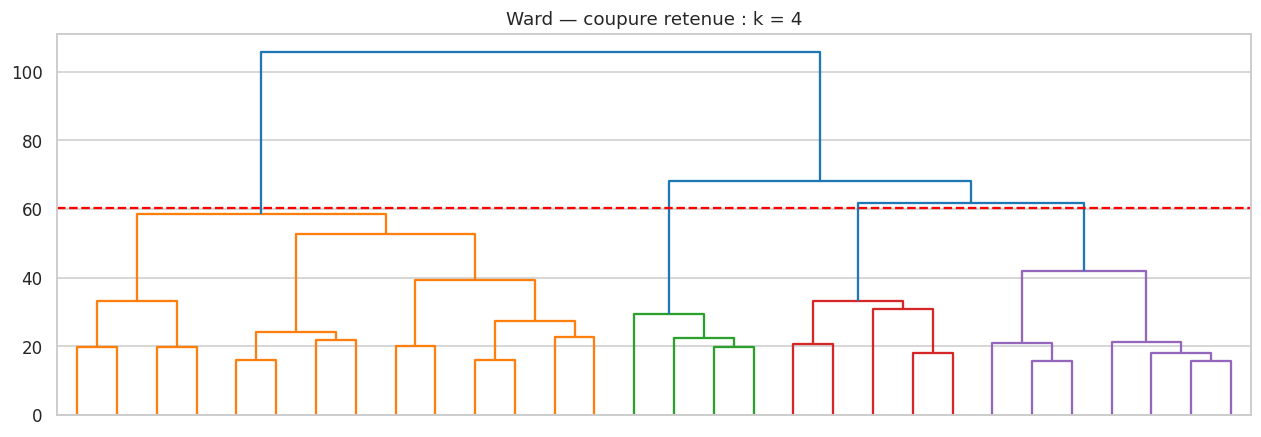

In [8]:
ward_sil = hac_df[(hac_df["distance"] == "euclidienne") & (hac_df["lien"] == "ward")].set_index("k")["silhouette"]
# k = 2 maximise mécaniquement la silhouette mais n'est pas actionnable (3-4 segments visés) → max sur k ≥ 3
k_ward = int(ward_sil.loc[3:].idxmax())
z = Z[("euclidienne", "ward")]
cut_h = (z[-k_ward, 2] + z[-k_ward + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(14, 4.5))
dendrogram(z, truncate_mode="lastp", p=30, ax=ax, no_labels=True, color_threshold=cut_h)
ax.axhline(cut_h, ls="--", color="red"); ax.set_title(f"Ward — coupure retenue : k = {k_ward}")
save(fig, "j3_ward_coupure")
lab_ward = hac_labels[("euclidienne", "ward", k_ward)]
print("k Ward =", k_ward, "| tailles :", np.bincount(lab_ward))

## 2. DBSCAN — réglage de $\varepsilon$ et `min_samples` par les k-distances
Règle usuelle : `min_samples` ($e^*$) $\geq$ dim + 1, souvent $2\times$dim. On trace la distance au $e^*$-ième plus proche voisin, triée ; $\varepsilon$ ($d^*$) est lu au **coude** de la courbe (point de courbure maximale).

{'UMAP 2D (e*=10)': np.float64(0.22706553754313286),
 'UMAP 2D (e*=50)': np.float64(0.5246413191555648),
 'PCA 80 % (7D)': np.float64(1.5098013183363106)}

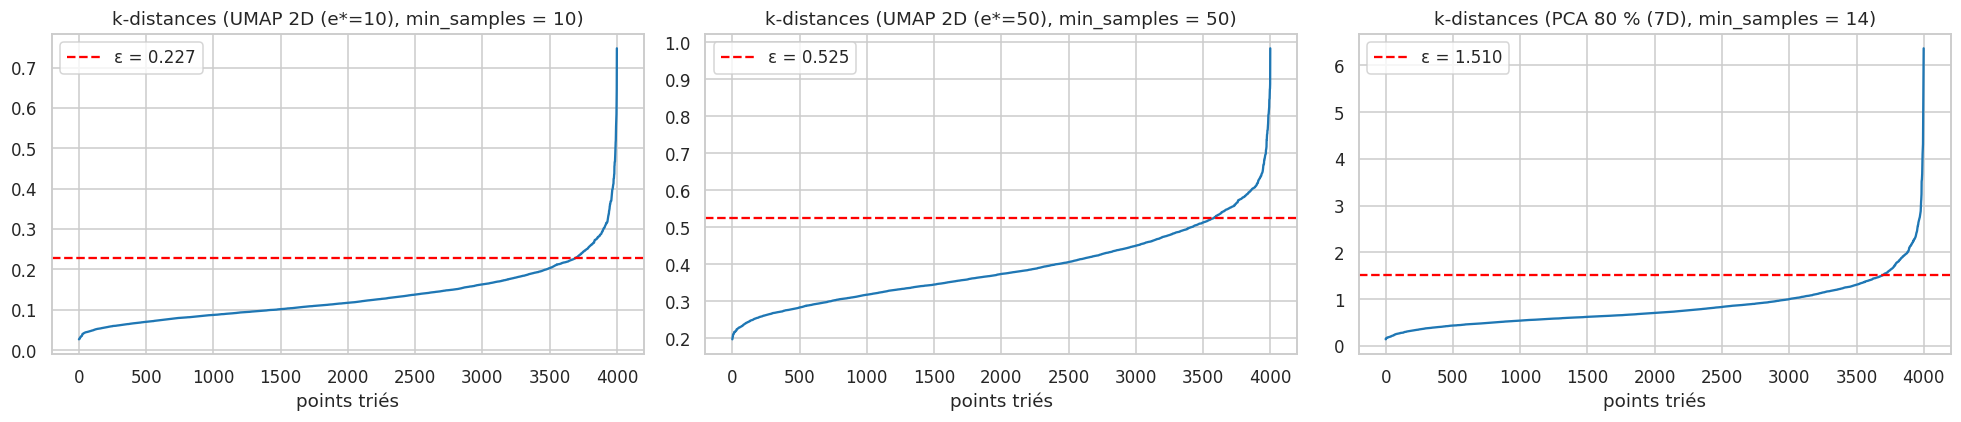

In [9]:
def kdist_eps(Xe, min_samples):
    nn = NearestNeighbors(n_neighbors=min_samples).fit(Xe)
    dist = np.sort(nn.kneighbors(Xe)[0][:, -1])
    return dist, dist[knee_point(dist)]

configs = {"UMAP 2D (e*=10)": (U, 10), "UMAP 2D (e*=50)": (U, 50), "PCA 80 % (7D)": (P, 14)}
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
eps_found = {}
for ax, (name, (Xe, ms)) in zip(axes, configs.items()):
    dist, eps = kdist_eps(Xe, ms); eps_found[name] = eps
    ax.plot(dist); ax.axhline(eps, ls="--", color="red", label=f"ε = {eps:.3f}")
    ax.set_title(f"k-distances ({name}, min_samples = {ms})"); ax.set_xlabel("points triés"); ax.legend()
fig.tight_layout(); save(fig, "j3_kdistances")
eps_found

In [10]:
rows, db_labels = [], {}
for name, (Xe, ms) in configs.items():
    for f in [0.75, 1.0, 1.5]:                       # sensibilité autour de ε*
        eps = eps_found[name] * f
        db = DBSCAN(eps=eps, min_samples=ms).fit(Xe)
        lab = db.labels_
        core = np.zeros(len(lab), bool); core[db.core_sample_indices_] = True
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        m = lab != -1
        rows.append({"espace": name, "min_samples": ms, "facteur": f, "eps": eps, "n_clusters": n_cl,
                     "cœur": int(core.sum()), "bordure": int((m & ~core).sum()), "bruit": int((~m).sum()),
                     "silhouette (espace)": silhouette_score(Xe[m], lab[m]) if n_cl > 1 else np.nan,
                     "silhouette (a)": silhouette_score(Xs[m], lab[m]) if n_cl > 1 else np.nan})
        db_labels[(name, f)] = (lab, core)
db_df = pd.DataFrame(rows); db_df.round(3)

,espace,min_samples,facteur,eps,n_clusters,cœur,bordure,bruit,silhouette (espace),silhouette (a)
0,UMAP 2D (e*=10),10,0.75,0.170,44,3125,503,372,0.366,0.053
1,UMAP 2D (e*=10),10,1.00,0.227,17,3689,231,80,0.375,0.056
2,UMAP 2D (e*=10),10,1.50,0.341,6,3941,45,14,0.457,0.044
3,UMAP 2D (e*=50),50,0.75,0.393,20,2312,1374,314,0.479,0.074
4,UMAP 2D (e*=50),50,1.00,0.525,6,3579,410,11,0.445,0.104
5,UMAP 2D (e*=50),50,1.50,0.787,4,3984,16,0,0.782,0.155
6,PCA 80 % (7D),14,0.75,1.132,6,3237,346,417,0.172,0.114
7,PCA 80 % (7D),14,1.00,1.510,3,3695,140,165,0.149,0.121
8,PCA 80 % (7D),14,1.50,2.265,1,3925,50,25,NaN,NaN


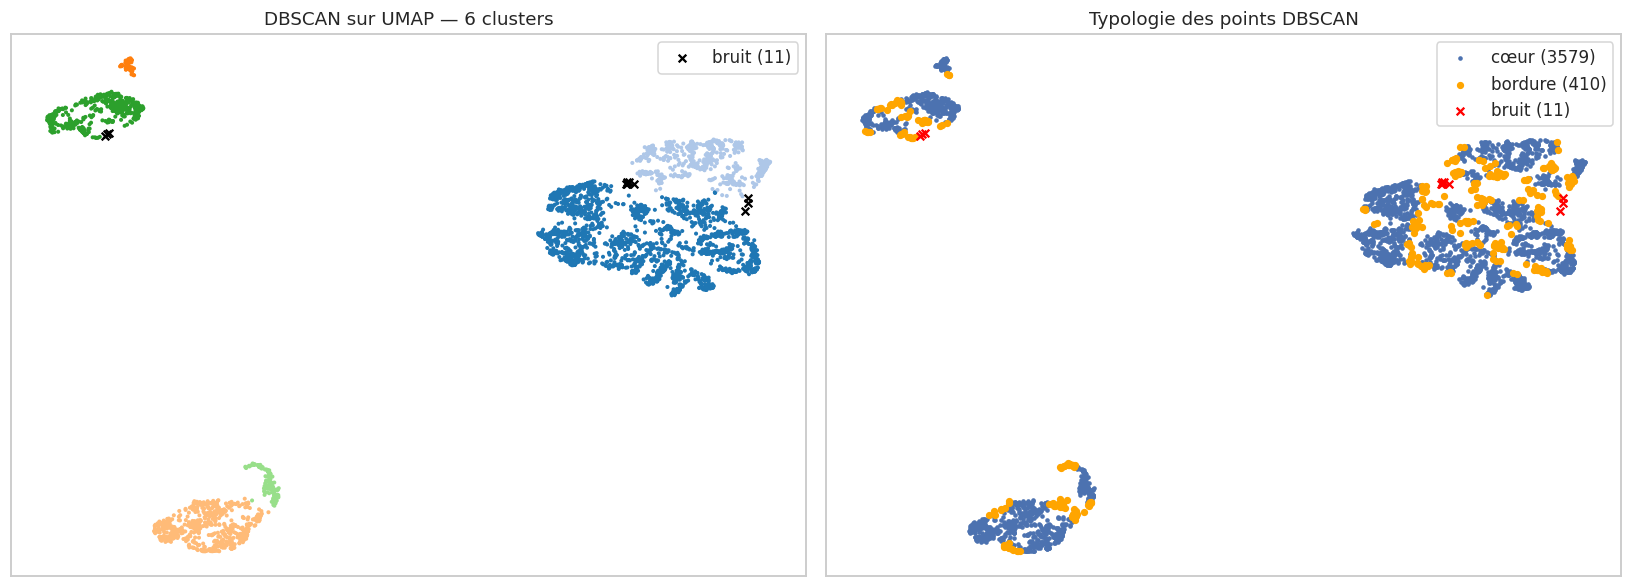

In [11]:
lab_db, core_db = db_labels[("UMAP 2D (e*=50)", 1.0)]
border = (lab_db != -1) & ~core_db; noise = lab_db == -1
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(x=U[~noise, 0], y=U[~noise, 1], hue=lab_db[~noise], palette="tab20", s=7, linewidth=0, ax=axes[0], legend=False)
axes[0].scatter(U[noise, 0], U[noise, 1], c="black", marker="x", s=25, label=f"bruit ({noise.sum()})")
axes[0].legend(); axes[0].set_title(f"DBSCAN sur UMAP — {len(set(lab_db)) - (-1 in lab_db)} clusters")
axes[1].scatter(U[core_db, 0], U[core_db, 1], s=4, c="#4C72B0", label=f"cœur ({core_db.sum()})")
axes[1].scatter(U[border, 0], U[border, 1], s=14, c="orange", label=f"bordure ({border.sum()})")
axes[1].scatter(U[noise, 0], U[noise, 1], s=25, c="red", marker="x", label=f"bruit ({noise.sum()})")
axes[1].legend(); axes[1].set_title("Typologie des points DBSCAN")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); save(fig, "j3_dbscan_umap")

In [12]:
cl = d["clean"].iloc[idx].reset_index(drop=True)
prof = cl.assign(cluster=lab_db).groupby("cluster").agg(
    n=("age", "size"), age=("age", "mean"), euribor=("euribor3m", "mean"), previous=("previous", "mean"),
    cellular=("contact_cellular", "mean"), poutcome=("poutcome", lambda s: s.mode()[0]),
    job=("job", lambda s: s.mode()[0])).round(2)
prof

,n,age,euribor,previous,cellular,poutcome,job
cluster,,,,,,,
-1,11,52.18,3.77,0.27,0.27,nonexistent,blue-collar
0,1970,42.59,4.83,0.00,0.49,nonexistent,blue-collar
1,638,33.27,4.81,0.00,0.56,nonexistent,admin.
2,83,41.11,4.11,1.00,0.94,failure,admin.
3,670,37.94,1.29,0.00,0.90,nonexistent,blue-collar
4,484,39.92,1.10,1.32,0.94,failure,admin.
5,144,48.00,0.82,0.00,0.85,nonexistent,admin.


**Lecture.**
- Avec $e^*=10$ (règle $\geq 2\times$dim), le coude donne $\varepsilon^*=0{,}23$ et **17 micro-clusters** : UMAP crée des îlots locaux très fins. Avec $e^*=50$ (lissage de la densité), $\varepsilon^*=0{,}52$ et on obtient **6 clusters** + **11 points de bruit** (0,3 %), 3 579 points cœur et 410 de bordure : c'est la configuration retenue.
- Sensibilité forte à $\varepsilon$ : ×0,75 → 20 clusters et 314 bruits ; ×1,5 → 4 clusters et plus de bruit du tout.
- Les clusters ont un sens métier clair : **période de taux élevés** (euribor ≈ 4,8) sans contact antérieur, séparée en clients ~43 ans (cluster 0, 1 970) et jeunes ~33 ans (cluster 1) ; **période de taux bas** (euribor ≈ 1,1–1,3) avec ou sans historique (`poutcome = failure`) ; seniors en période de taux bas (cluster 5, 48 ans).
- Les points de bruit sont plus âgés (52 ans en moyenne) : profils atypiques, exploités dans le bonus « anomalies ».
- Dans l'espace PCA 7D, la densité est plus diffuse (concentration des distances en dimension élevée) : 3 clusters et 4 % de bruit à $\varepsilon^*$, 1 seul cluster à ×1,5.
- Attention : les distances UMAP ne sont pas des distances métier ; on interprète les clusters a posteriori via les variables d'origine.

## 3. Limites de K-means face à DBSCAN
### 3.1 Démonstration contrôlée (lunes + points isolés)

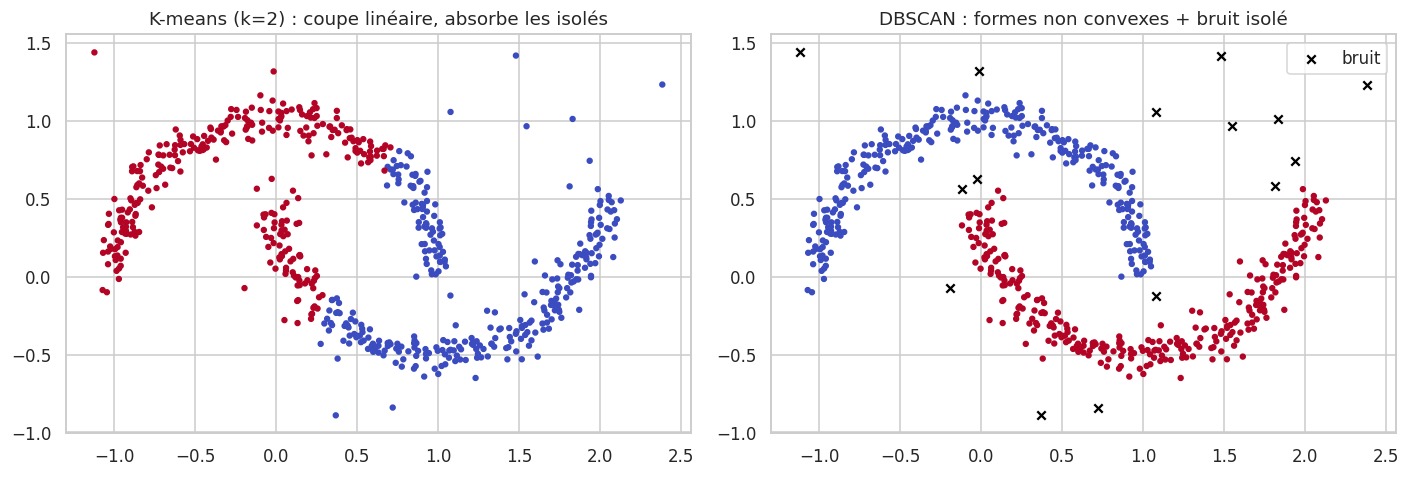

In [13]:
Xm, _ = make_moons(600, noise=0.06, random_state=SEED)
rng = np.random.default_rng(SEED); outl = rng.uniform([-1.5, -1], [2.5, 1.5], (25, 2))
Xm = np.vstack([Xm, outl])
km_m = KMeans(2, n_init=10, random_state=SEED).fit_predict(Xm)
db_m = DBSCAN(eps=0.15, min_samples=8).fit_predict(Xm)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(Xm[:, 0], Xm[:, 1], c=km_m, cmap="coolwarm", s=10); axes[0].set_title("K-means (k=2) : coupe linéaire, absorbe les isolés")
axes[1].scatter(Xm[db_m >= 0, 0], Xm[db_m >= 0, 1], c=db_m[db_m >= 0], cmap="coolwarm", s=10)
axes[1].scatter(Xm[db_m < 0, 0], Xm[db_m < 0, 1], c="k", marker="x", s=30, label="bruit")
axes[1].legend(); axes[1].set_title("DBSCAN : formes non convexes + bruit isolé")
fig.tight_layout(); save(fig, "j3_kmeans_vs_dbscan_moons")

### 3.2 Sur nos données (espace UMAP)

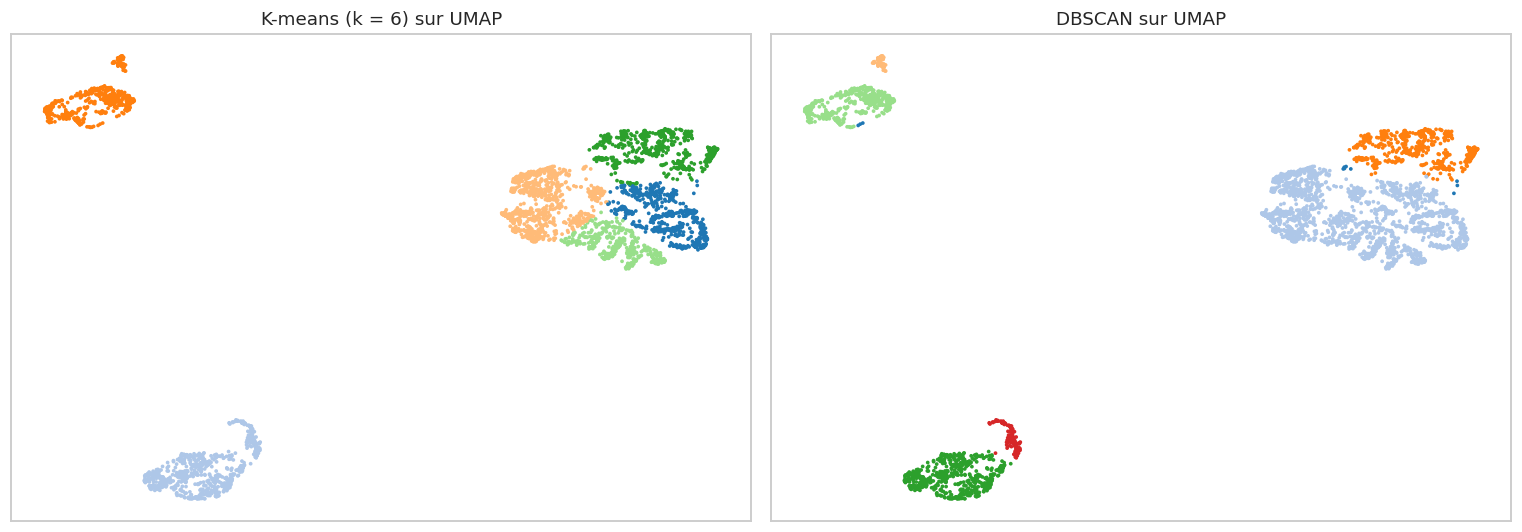

In [14]:
n_db = len(set(lab_db)) - (-1 in lab_db)
km_u = KMeans(n_db, n_init=10, random_state=SEED).fit_predict(U)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=U[:, 0], y=U[:, 1], hue=km_u, palette="tab20", s=6, linewidth=0, ax=axes[0], legend=False)
axes[0].set_title(f"K-means (k = {n_db}) sur UMAP")
sns.scatterplot(x=U[:, 0], y=U[:, 1], hue=lab_db, palette="tab20", s=6, linewidth=0, ax=axes[1], legend=False)
axes[1].set_title("DBSCAN sur UMAP")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); save(fig, "j3_kmeans_vs_dbscan_umap")

**Discussion**
| | K-means | DBSCAN |
|---|---|---|
| Forme des clusters | convexes, sphériques (Voronoï) | quelconque (connexité par densité) |
| Nombre de clusters | à fixer ($k$) | déduit de la densité |
| Points isolés | **absorbés** et déplacent les centroïdes | étiquetés **bruit** |
| Densités hétérogènes | tailles de clusters « forcées » | un seul ε → difficulté si densités très différentes |
| Grande dimension | correct (moyennes) | dégradé (distances concentrées) → travailler sur UMAP/PCA |
| Affectation d'un nouveau client | immédiate (centroïde le plus proche) | non native |

K-means découpe les îlots UMAP de façon arbitraire (un îlot coupé en deux, deux îlots fusionnés), alors que DBSCAN suit la géométrie réelle. En revanche, DBSCAN ne propose pas de modèle prédictif pour un nouveau client et dépend fortement de $\varepsilon$ : c'est une bonne méthode **exploratoire et de détection d'atypiques** (cf. bonus), moins un outil de segmentation opérationnelle.

In [15]:
joblib.dump({"hac": hac_labels, "k_ward": k_ward,
             "dbscan_umap": db_labels[("UMAP 2D (e*=50)", 1.0)][0], "dbscan_umap_fin": db_labels[("UMAP 2D (e*=10)", 1.0)][0], "dbscan_pca": db_labels[("PCA 80 % (7D)", 1.0)][0],
             "eps": eps_found}, RESULTS / "j3_labels.joblib")
hac_df.to_csv(RESULTS / "j3_cah.csv", index=False); db_df.to_csv(RESULTS / "j3_dbscan.csv", index=False)
pd.Series(coph).to_csv(RESULTS / "j3_cophenetique.csv")
print("Résultats sauvegardés.")

Résultats sauvegardés.
